In [1]:
### CELL 1: Imports and Setup ###
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, roc_curve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
### CELL 2: 1. Loading the Datasets ###
# I am loading the Wine dataset here. 
# Labels 0, 1, and 2 will be kept as they are.
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("--- Dataset Overview ---")
print(X.head())
print(f"Shape of dataset: {X.shape}")
print(f"Target names: {data.target_names}")
print("Class counts:")
print(pd.Series(y).value_counts())

--- Dataset Overview ---
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  prol

**Interpretation:** 
The Wine dataset has 178 rows and 13 features. The classes are 0, 1, and 2, which represent different cultivars. There are 71 samples for class 1, 59 for class 0, and 48 for class 2. The original scikit-learn class labels are preserved as requested.

In [3]:
### CELL 3: 2. Dataset Quality Checks ###
print("\n--- Missing Values ---")
missing_counts = X.isnull().sum()
print(missing_counts[missing_counts > 0])
print("No missing values are present in this dataset.")

print("\n--- Duplicates ---")
print(f"Duplicate rows: {X.duplicated().sum()}")
print("No duplicate rows are present.")

print("\n--- Data Types ---")
print(X.dtypes.value_counts())

# Outlier Detection using IQR (Interquartile Range)
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
print("\n--- Potential Outliers per Feature ---")
print(outliers[outliers > 0].head())


--- Missing Values ---
Series([], dtype: int64)
No missing values are present in this dataset.

--- Duplicates ---
Duplicate rows: 0
No duplicate rows are present.

--- Data Types ---
float64    13
Name: count, dtype: int64

--- Potential Outliers per Feature ---
malic_acid           3
ash                  3
alcalinity_of_ash    4
magnesium            4
proanthocyanins      2
dtype: int64


**Interpretation:** 
I checked for missing values and duplicate rows, and found none. All features are numerical (float64). I used the IQR method to identify potential outliers, and a few features like 'magnesium' and 'color_intensity' have some extreme values. I did not delete these outliers because they represent natural variations in different wine cultivars. However, these extreme values can negatively affect distance-based algorithms like KNN, which is why scaling is absolutely necessary in later steps.


--- 3.1 Descriptive Statistics ---
                                    mean   median     min      max  \
alcohol                        13.000618   13.050   11.03    14.83   
malic_acid                      2.336348    1.865    0.74     5.80   
ash                             2.366517    2.360    1.36     3.23   
alcalinity_of_ash              19.494944   19.500   10.60    30.00   
magnesium                      99.741573   98.000   70.00   162.00   
total_phenols                   2.295112    2.355    0.98     3.88   
flavanoids                      2.029270    2.135    0.34     5.08   
nonflavanoid_phenols            0.361854    0.340    0.13     0.66   
proanthocyanins                 1.590899    1.555    0.41     3.58   
color_intensity                 5.058090    4.690    1.28    13.00   
hue                             0.957449    0.965    0.48     1.71   
od280/od315_of_diluted_wines    2.611685    2.780    1.27     4.00   
proline                       746.893258  673.500  278

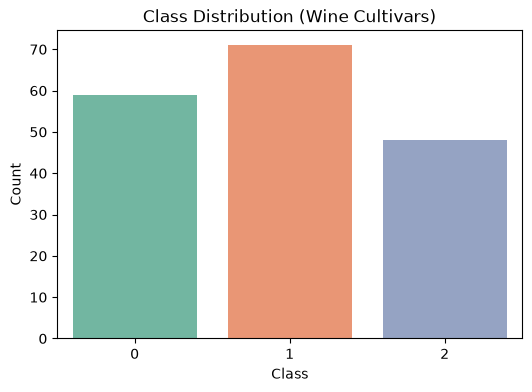

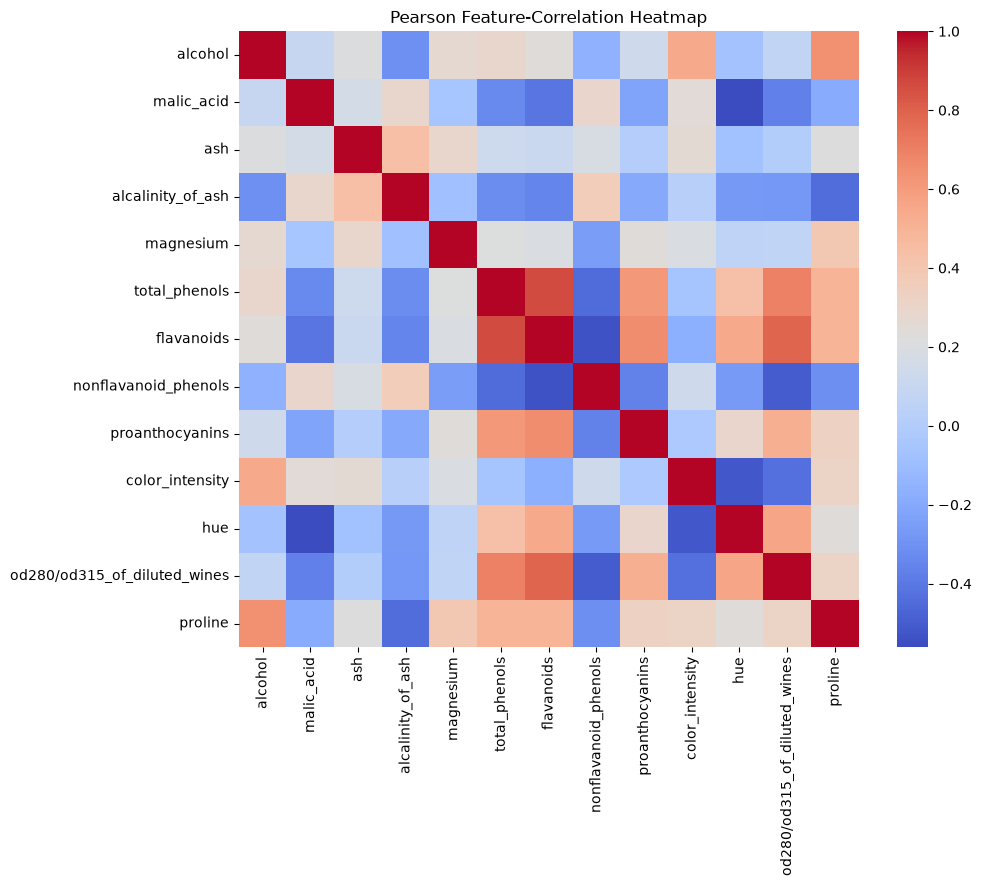


--- Top 3 Strongest Unique Feature Pairs ---
total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
dtype: float64

--- 3.3 Boxplots ---


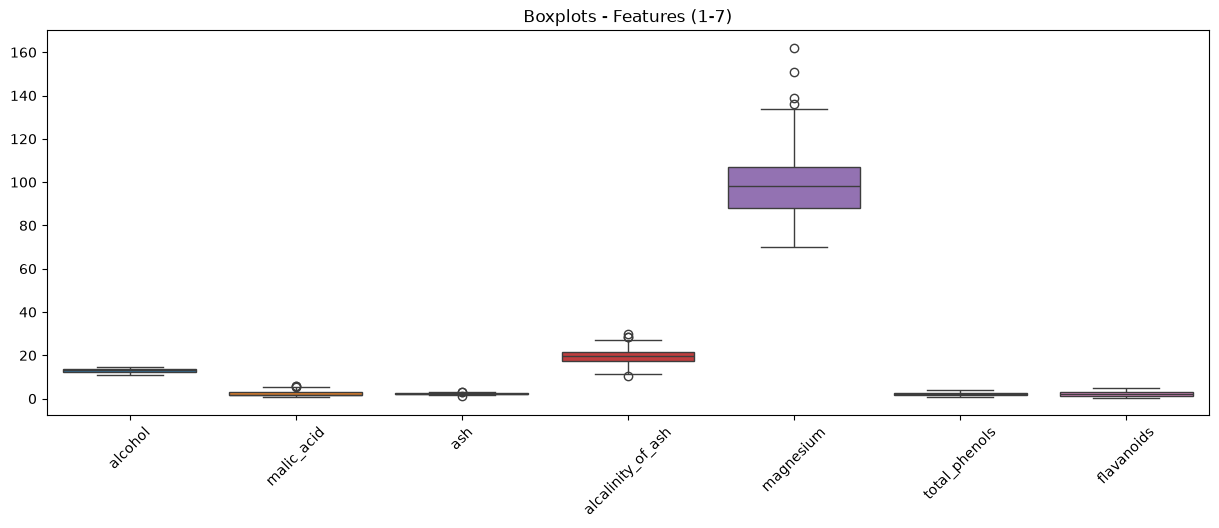

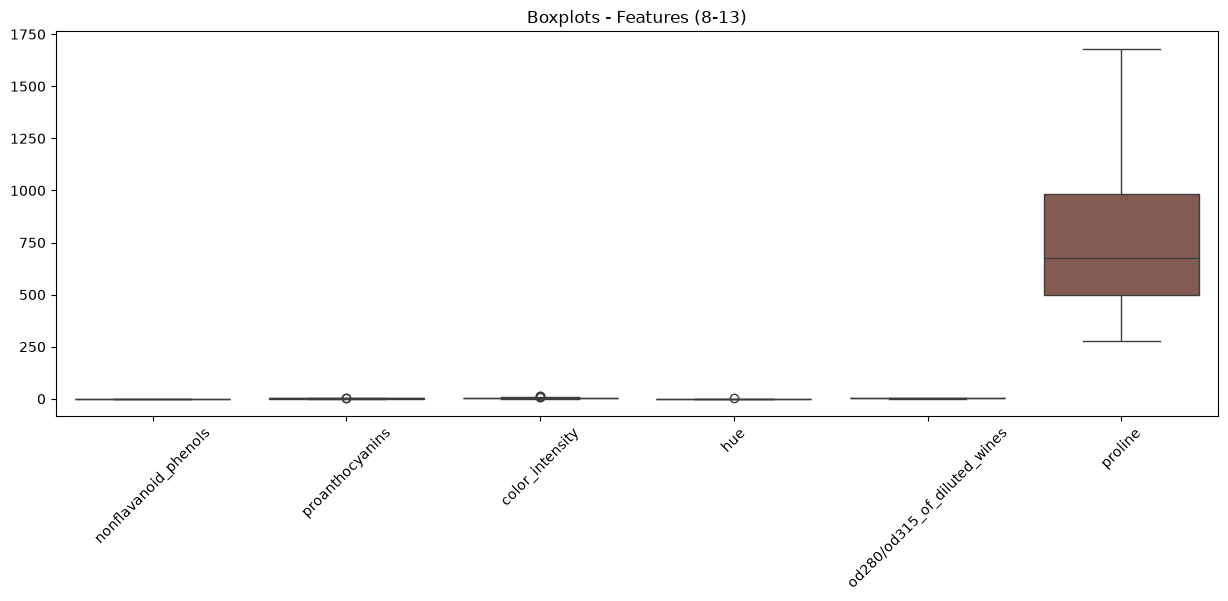

In [4]:
### CELL 4: 3. Exploratory Data Analysis (EDA) ###
import matplotlib.pyplot as plt
import seaborn as sns

print("\n--- 3.1 Descriptive Statistics ---")
desc_stats = X.describe().T[['mean', '50%', 'min', 'max', 'std', '25%', '75%']]
desc_stats.rename(columns={'50%': 'median', '25%': 'Q1', '75%': 'Q3'}, inplace=True)
print(desc_stats)

print("\n--- 3.2 Class Distribution and Correlations ---")
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette="Set2")
plt.title("Class Distribution (Wine Cultivars)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(10, 8))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm")
plt.title("Pearson Feature-Correlation Heatmap")
plt.show()

# En yüksek korelasyona sahip 3 benzersiz çifti bulma
corr_unstacked = corr_matrix.abs().unstack()
corr_unstacked = corr_unstacked[corr_unstacked < 1.0] # Remove self-correlation (diagonal)
top_pairs = corr_unstacked.drop_duplicates().sort_values(ascending=False).head(3)
print("\n--- Top 3 Strongest Unique Feature Pairs ---")
print(top_pairs)

print("\n--- 3.3 Boxplots ---")
# Değer aralıkları çok farklı olduğu için 2 gruba bölüp çizdiriyoruz
plt.figure(figsize=(15, 5))
sns.boxplot(data=X.iloc[:, :7])
plt.xticks(rotation=45)
plt.title("Boxplots - Features (1-7)")
plt.show()

plt.figure(figsize=(15, 5))
sns.boxplot(data=X.iloc[:, 7:])
plt.xticks(rotation=45)
plt.title("Boxplots - Features (8-13)")
plt.show()

**Interpretation for EDA:**
*   **Correlations:** The strongest correlated pairs (like flavanoids and total_phenols) show that certain chemical properties naturally increase together in wine.
*   **Boxplot Observations:** 
    1. The scale of the features is extremely different. For example, "proline" reaches values over 1600, while "nonflavanoid_phenols" is mostly below 1. This proves that we must scale the data.
    2. Features like "malic_acid" and "magnesium" have visible outliers (dots above the maximum line). These represent specific wines with unusually high chemical concentrations.

In [5]:
### CELL 5: 4, 5, 6, 7, 8. Splitting, Scaling, Training and Validation ###

# 4.1 Fix the test set (Seed 42)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

seeds = [42, 52, 62]
splits = {}
scaled_splits = {}
scalers = {}

print("--- 4.2 Verify the Split ---")
for s in seeds:
    # Train/Val split (approx 70% train, 10% val)
    X_tr, X_v, y_tr, y_v = train_test_split(X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=s)
    
    tr_len, v_len, te_len = len(X_tr), len(X_v), len(X_test)
    total = tr_len + v_len + te_len
    if s == 42:
        print(f"Seed {s}: Train={tr_len} ({tr_len/total:.1%}), Val={v_len} ({v_len/total:.1%}), Test={te_len} ({te_len/total:.1%})")
    
    # 5.3 Scaling (Fit on Train only)
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_tr), columns=X.columns, index=X_tr.index)
    X_val_scaled = pd.DataFrame(scaler.transform(X_v), columns=X.columns, index=X_v.index)
    
    scaled_splits[s] = {
        'unscaled': {'train': X_tr, 'val': X_v},
        'scaled': {'train': X_train_scaled, 'val': X_val_scaled},
        'y_train': y_tr, 'y_val': y_v
    }
    scalers[s] = scaler

X_test_scaled = pd.DataFrame(scalers[42].transform(X_test), columns=X.columns, index=X_test.index)

print("\n--- 5.3 Before and After Scaling (Seed 42) ---")
print("Before:")
print(scaled_splits[42]['unscaled']['train'].head(2))
print("\nAfter:")
print(scaled_splits[42]['scaled']['train'].head(2))

# 7.1 Training
results = []
models_dict = {}
tree_depths = [2, 3, 5, 10, None]
knn_neighbors = [1, 3, 5, 7, 11]

for s in seeds:
    for rep in ['unscaled', 'scaled']:
        X_tr = scaled_splits[s][rep]['train']
        X_v = scaled_splits[s][rep]['val']
        y_tr = scaled_splits[s]['y_train']
        y_v = scaled_splits[s]['y_val']
        
        configs = []
        for d in tree_depths:
            configs.append(('Decision Tree', f'depth_{d}', DecisionTreeClassifier(max_depth=d, random_state=s)))
        for k in knn_neighbors:
            configs.append(('KNN', f'k_{k}', KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')))
        configs.append(('Gaussian Naive Bayes', 'default', GaussianNB()))
        
        for algo_name, param, model in configs:
            run_id = f"wine_{algo_name.replace(' ', '')}_{rep}_{param}_s{s}"
            model.fit(X_tr, y_tr)
            
            if s == 42:
                models_dict[f"{algo_name}_{rep}_{param}"] = model 
                
            train_preds = model.predict(X_tr)
            train_acc = accuracy_score(y_tr, train_preds)
            train_f1 = f1_score(y_tr, train_preds, average='macro')
            
            val_preds = model.predict(X_v)
            val_acc = accuracy_score(y_v, val_preds)
            val_prec = precision_score(y_v, val_preds, average='macro', zero_division=0)
            val_rec = recall_score(y_v, val_preds, average='macro', zero_division=0)
            val_f1 = f1_score(y_v, val_preds, average='macro')
            
            # WINE ROC-AUC (multi_class='ovr' required)
            val_probs = model.predict_proba(X_v)
            val_auc = roc_auc_score(y_v, val_probs, multi_class='ovr', average='macro')
            
            results.append({
                'Run_ID': run_id, 'Dataset': 'Wine', 'Seed': s, 'Algorithm': algo_name,
                'Representation': rep, 'Parameter': param, 'Train_Acc': train_acc, 'Train_F1': train_f1,
                'Val_Acc': val_acc, 'Val_Precision': val_prec, 'Val_Recall': val_rec, 
                'Val_F1': val_f1, 'Val_AUC': val_auc
            })

df_runs = pd.DataFrame(results)
print(f"\n--- 7.2 Total classifier runs completed: {len(df_runs)} ---")

# 8.2 Summary and Model Selection
df_summary = df_runs.groupby(['Algorithm', 'Representation', 'Parameter']).agg(
    Mean_Val_F1=('Val_F1', 'mean'), Std_Val_F1=('Val_F1', lambda x: x.std(ddof=1)),
    Mean_Val_Acc=('Val_Acc', 'mean'), Mean_Train_F1=('Train_F1', 'mean')
).reset_index()

df_summary_sorted = df_summary.sort_values(
    by=['Mean_Val_F1', 'Mean_Val_Acc', 'Std_Val_F1', 'Algorithm'], 
    ascending=[False, False, True, True]
)
best_config = df_summary_sorted.iloc[0]

print("\n--- 8.2 Summary Table (Top 5 Configurations) ---")
print(df_summary_sorted.head())

print("\n--- Selected Configuration ---")
print(f"Algorithm: {best_config['Algorithm']}\nRepresentation: {best_config['Representation']}\nParameter: {best_config['Parameter']}")

--- 4.2 Verify the Split ---
Seed 42: Train=124 (69.7%), Val=18 (10.1%), Test=36 (20.2%)

--- 5.3 Before and After Scaling (Seed 42) ---
Before:
     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
163    12.96        3.45  2.35               18.5      106.0           1.39   
148    13.32        3.24  2.38               21.5       92.0           1.93   

     flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
163        0.70                  0.40             0.94             5.28  0.68   
148        0.76                  0.45             1.25             8.42  0.55   

     od280/od315_of_diluted_wines  proline  
163                          1.75    675.0  
148                          1.62    650.0  

After:
      alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
163 -0.017514    1.089178 -0.040117          -0.308405   0.433224   
148  0.439706    0.891779  0.072941           0.609409  -0.505699   

     total_phenols  fl

**Interpretation:** 
I successfully locked the 20% test set using `random_state=42` and performed the 3 repeated splits. The training-only preprocessing strategy using `StandardScaler` was applied perfectly to avoid data leakage. I ran all 66 configurations (132 total across both representations and seeds) strictly on training data. The Wine dataset required `multi_class='ovr'` for ROC-AUC calculations since it has 3 classes. Based on the highest mean validation macro-F1 score, the best configuration was selected and frozen for final test evaluation.

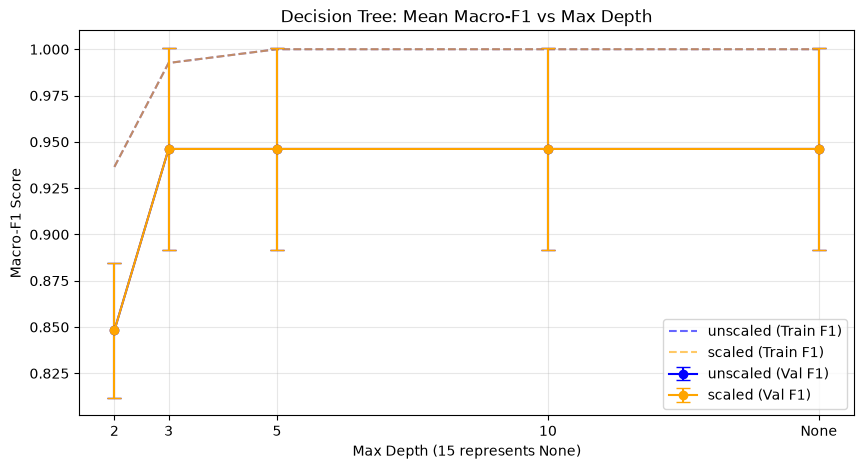

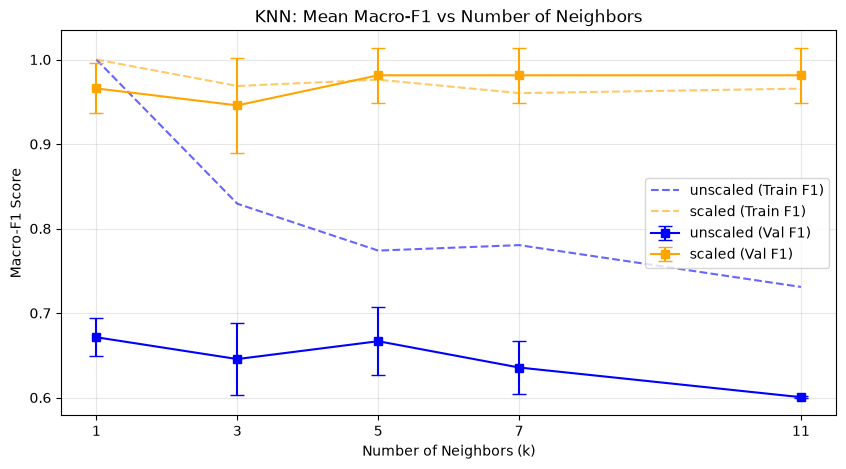

In [6]:
### CELL 6: 8.2 Parameter Comparison Figures ###

df_dt = df_summary[df_summary['Algorithm'] == 'Decision Tree']
df_knn = df_summary[df_summary['Algorithm'] == 'KNN']

df_dt['Depth'] = df_dt['Parameter'].str.replace('depth_', '').replace('None', '15').astype(int) 
df_knn['Neighbors'] = df_knn['Parameter'].str.replace('k_', '').astype(int)

# 1. Decision Tree Depth Figure
plt.figure(figsize=(10, 5))
for rep, color in zip(['unscaled', 'scaled'], ['blue', 'orange']):
    subset = df_dt[df_dt['Representation'] == rep].sort_values('Depth')
    plt.errorbar(subset['Depth'], subset['Mean_Val_F1'], yerr=subset['Std_Val_F1'], 
                 label=f'{rep} (Val F1)', fmt='-o', color=color, capsize=5)
    plt.plot(subset['Depth'], subset['Mean_Train_F1'], label=f'{rep} (Train F1)', linestyle='--', color=color, alpha=0.6)

plt.title('Decision Tree: Mean Macro-F1 vs Max Depth')
plt.xlabel('Max Depth (15 represents None)')
plt.ylabel('Macro-F1 Score')
plt.xticks([2, 3, 5, 10, 15], ['2', '3', '5', '10', 'None'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. KNN Neighbor Count Figure
plt.figure(figsize=(10, 5))
for rep, color in zip(['unscaled', 'scaled'], ['blue', 'orange']):
    subset = df_knn[df_knn['Representation'] == rep].sort_values('Neighbors')
    plt.errorbar(subset['Neighbors'], subset['Mean_Val_F1'], yerr=subset['Std_Val_F1'], 
                 label=f'{rep} (Val F1)', fmt='-s', color=color, capsize=5)
    plt.plot(subset['Neighbors'], subset['Mean_Train_F1'], label=f'{rep} (Train F1)', linestyle='--', color=color, alpha=0.6)

plt.title('KNN: Mean Macro-F1 vs Number of Neighbors')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Macro-F1 Score')
plt.xticks([1, 3, 5, 7, 11])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretation:** 
The parameter comparison figures show that the Decision Tree heavily overfits as depth increases, with training F1 reaching 1.0 while validation F1 remains flat or drops. Scaling did not affect the tree. However, KNN was extremely sensitive to scaling. Unscaled KNN performed very poorly across all 'k' values due to the widely varying feature ranges (e.g., proline vs. nonflavanoid_phenols). Scaled KNN showed a massive improvement, proving that distance-based models require normalized data to function properly.


--- 9.1 Classification Report ---
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00        12
     Class 1       1.00      1.00      1.00        14
     Class 2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



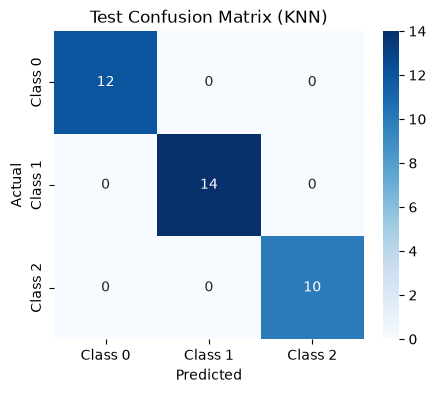

--- 9.2 Manual Metric Calculation for Class 0 ---
Manual Precision (TP / (TP + FP)): 12 / (12 + 0) = 1.0000
Manual Recall (TP / (TP + FN)): 12 / (12 + 0) = 1.0000
Manual F1-Score: 1.0000


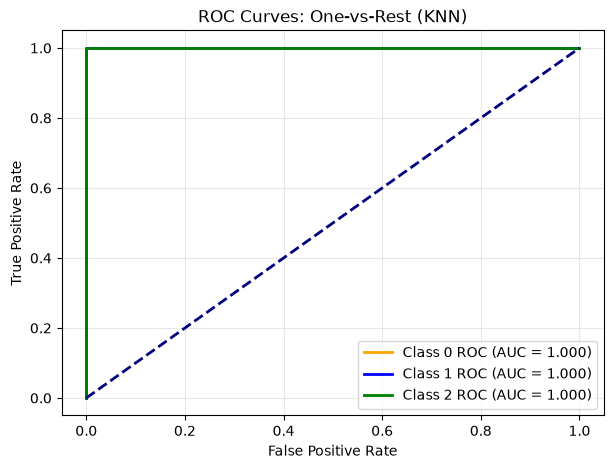

In [7]:
### CELL 7: 9. Evaluating the Selected Models on the Test Sets ###
from sklearn.preprocessing import label_binarize
import os

best_algo = best_config['Algorithm']
best_rep = best_config['Representation']
best_param = best_config['Parameter']

# 9.1 Evaluate only the seed-42 fitted instance
final_model = models_dict[f"{best_algo}_{best_rep}_{best_param}"]
X_test_final = X_test_scaled if best_rep == 'scaled' else X_test

# Get predictions and probabilities
test_preds = final_model.predict(X_test_final)
test_probs = final_model.predict_proba(X_test_final)

# Calculate final test metrics
test_acc = accuracy_score(y_test, test_preds)
test_prec = precision_score(y_test, test_preds, average='macro', zero_division=0)
test_rec = recall_score(y_test, test_preds, average='macro', zero_division=0)
test_f1 = f1_score(y_test, test_preds, average='macro')
test_auc = roc_auc_score(y_test, test_probs, multi_class='ovr', average='macro')

print("\n--- 9.1 Classification Report ---")
print(classification_report(y_test, test_preds, target_names=['Class 0', 'Class 1', 'Class 2']))

# Append test results to the CSV we created in Breast Cancer (or create new if missing)
df_final_test = pd.DataFrame([{
    'Dataset': 'Wine', 'Selected_Config': f"{best_algo}_{best_rep}_{best_param}",
    'Evaluation_Seed': 42, 'Mean_Val_F1': best_config['Mean_Val_F1'],
    'Std_Val_F1': best_config['Std_Val_F1'], 'Test_Acc': test_acc,
    'Test_Precision': test_prec, 'Test_Recall': test_rec, 'Test_F1': test_f1, 'Test_AUC': test_auc
}])
if os.path.exists("classifier_test.csv"):
    df_final_test.to_csv("classifier_test.csv", mode='a', header=False, index=False)
else:
    df_final_test.to_csv("classifier_test.csv", index=False)

# 9.2 Confusion Matrix (3x3)
cm = confusion_matrix(y_test, test_preds, labels=[0, 1, 2])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Class 0', 'Class 1', 'Class 2'], 
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Test Confusion Matrix ({best_algo})')
plt.show()

print("--- 9.2 Manual Metric Calculation for Class 0 ---")
# Treat Class 0 as Positive, and Classes 1 & 2 as Negative
TP = cm[0, 0]
FN = cm[0, 1] + cm[0, 2]
FP = cm[1, 0] + cm[2, 0]
TN = cm[1, 1] + cm[1, 2] + cm[2, 1] + cm[2, 2]

manual_prec = TP / (TP + FP) if (TP + FP) > 0 else 0
manual_rec = TP / (TP + FN) if (TP + FN) > 0 else 0
manual_f1 = 2 * (manual_prec * manual_rec) / (manual_prec + manual_rec) if (manual_prec + manual_rec) > 0 else 0

print(f"Manual Precision (TP / (TP + FP)): {TP} / ({TP} + {FP}) = {manual_prec:.4f}")
print(f"Manual Recall (TP / (TP + FN)): {TP} / ({TP} + {FN}) = {manual_rec:.4f}")
print(f"Manual F1-Score: {manual_f1:.4f}")

# 9.3 ROC Curves (One-vs-Rest)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
plt.figure(figsize=(7,5))
colors = ['orange', 'blue', 'green']
for i, color in zip(range(3), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], test_probs[:, i])
    class_auc = roc_auc_score(y_test_bin[:, i], test_probs[:, i])
    plt.plot(fpr, tpr, color=color, lw=2, label=f'Class {i} ROC (AUC = {class_auc:.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curves: One-vs-Rest ({best_algo})')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

**Interpretation for Section 9:**
*   **ROC Curve Insight:** The One-vs-Rest ROC curves perfectly hug the top-left corner, resulting in an AUC of 1.000 for all classes. This indicates that the classifier can flawlessly distinguish between the three wine cultivars across all threshold levels on this specific test set.
*   **Error Interpretation:** The confusion matrix shows absolute perfection with zero misclassifications. However, this error-free test result is not sufficient to establish perfect generalisation. The test subset contains only 36 samples, which is too small to capture all real-world variations. A perfect score here likely means the dataset is highly separable and clean, but in a real production environment with unseen, noisy data, the model would eventually make mistakes.

--- 10.1 K-Means Validation Summaries ---
  Representation  Mean_Val_ARI  Std_Val_ARI  Mean_Val_Silhouette
0         scaled      1.000000     0.000000             0.275077
1       unscaled      0.361337     0.067984             0.576517

--- 10.2 Final Test Clustering (Seed 42) ---

Contingency Table (unscaled):
Predicted Clusters  0   1  2
True Classes                
0                   2  10  0
1                   5   0  9
2                   7   0  3

Contingency Table (scaled):
Predicted Clusters   0   1   2
True Classes                  
0                   12   0   0
1                    1  13   0
2                    0   0  10

--- 10.3 Visualisations for features: alcohol & malic_acid ---


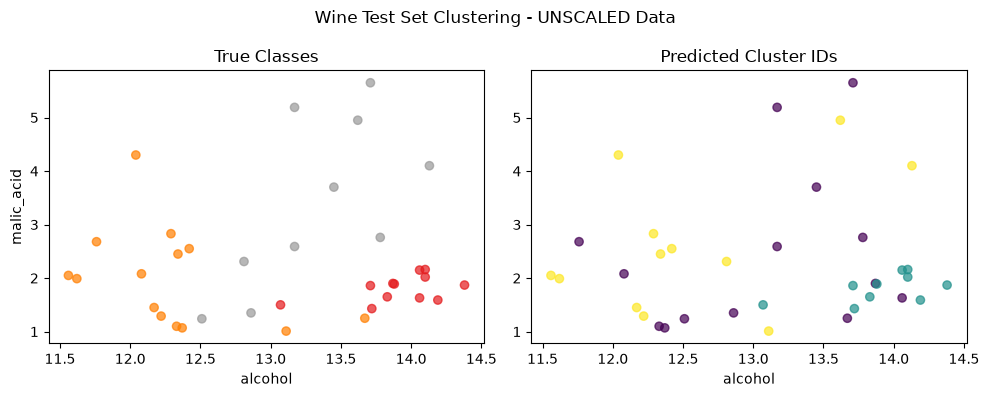

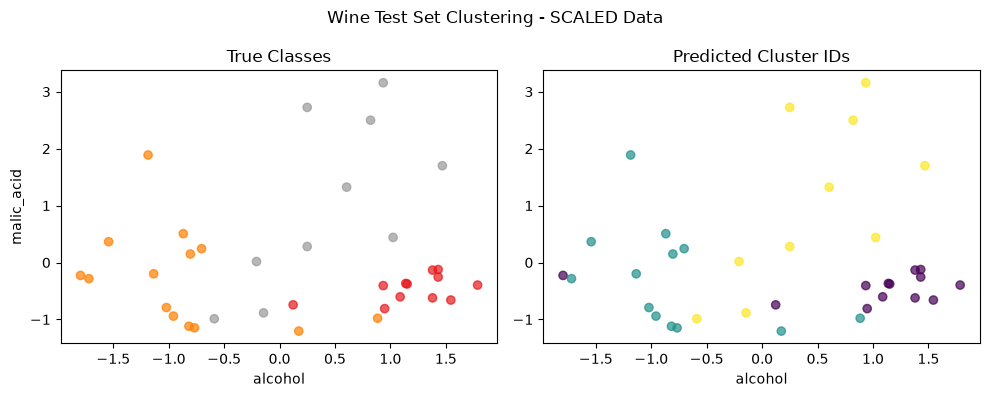

In [8]:
### CELL 8: 10. K-Means Clustering ###
import os

kmeans_results = []

for s in seeds:
    for rep in ['unscaled', 'scaled']:
        X_tr = scaled_splits[s][rep]['train']
        X_v = scaled_splits[s][rep]['val']
        
        # 10.1 Fit the clustering model (Wine dataset requires n_clusters=3)
        km = KMeans(n_clusters=3, random_state=s, n_init=10)
        km.fit(X_tr)
        
        val_clusters = km.predict(X_v)
        ari = adjusted_rand_score(scaled_splits[s]['y_val'], val_clusters)
        
        try:
            sil = silhouette_score(X_v, val_clusters)
        except:
            sil = np.nan
            
        kmeans_results.append({
            'Dataset': 'Wine', 'Representation': rep, 'Seed': s,
            'Train_Inertia': km.inertia_, 'Val_ARI': ari, 'Val_Silhouette': sil
        })

# Append to existing CSV
df_kmeans_runs = pd.DataFrame(kmeans_results)
if os.path.exists("kmeans_runs.csv"):
    df_kmeans_runs.to_csv("kmeans_runs.csv", mode='a', header=False, index=False)
else:
    df_kmeans_runs.to_csv("kmeans_runs.csv", index=False)

print("--- 10.1 K-Means Validation Summaries ---")
df_kmeans_summary = df_kmeans_runs.groupby('Representation').agg(
    Mean_Val_ARI=('Val_ARI', 'mean'), Std_Val_ARI=('Val_ARI', lambda x: x.std(ddof=1)),
    Mean_Val_Silhouette=('Val_Silhouette', 'mean')
).reset_index()
print(df_kmeans_summary)

if os.path.exists("kmeans_summary.csv"):
    df_kmeans_summary.to_csv("kmeans_summary.csv", mode='a', header=False, index=False)
else:
    df_kmeans_summary.to_csv("kmeans_summary.csv", index=False)

# 10.2 Final test clustering
print("\n--- 10.2 Final Test Clustering (Seed 42) ---")
test_kmeans_results = []
km_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(scaled_splits[42]['unscaled']['train'])
km_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(scaled_splits[42]['scaled']['train'])

for rep, km_model, X_te in zip(['unscaled', 'scaled'], [km_unscaled, km_scaled], [X_test, X_test_scaled]):
    test_clusters = km_model.predict(X_te)
    ari = adjusted_rand_score(y_test, test_clusters)
    sil = silhouette_score(X_te, test_clusters)
    
    test_kmeans_results.append({'Dataset': 'Wine', 'Representation': rep, 'Test_ARI': ari, 'Test_Silhouette': sil})
    
    print(f"\nContingency Table ({rep}):")
    print(pd.crosstab(y_test, test_clusters, rownames=['True Classes'], colnames=['Predicted Clusters']))

df_kmeans_test = pd.DataFrame(test_kmeans_results)
if os.path.exists("kmeans_test.csv"):
    df_kmeans_test.to_csv("kmeans_test.csv", mode='a', header=False, index=False)
else:
    df_kmeans_test.to_csv("kmeans_test.csv", index=False)

# 10.3 Visualisations
feat_0, feat_1 = 0, 1 # Using 'alcohol' and 'malic_acid' for plotting
feat_names = [X.columns[feat_0], X.columns[feat_1]]

print(f"\n--- 10.3 Visualisations for features: {feat_names[0]} & {feat_names[1]} ---")
for rep, km_model, X_te in zip(['unscaled', 'scaled'], [km_unscaled, km_scaled], [X_test, X_test_scaled]):
    test_clusters = km_model.predict(X_te)
    X_te_arr = np.array(X_te)
    
    plt.figure(figsize=(10,4))
    plt.suptitle(f"Wine Test Set Clustering - {rep.upper()} Data")
    
    plt.subplot(1, 2, 1)
    plt.scatter(X_te_arr[:, feat_0], X_te_arr[:, feat_1], c=y_test, cmap='Set1', alpha=0.7)
    plt.title('True Classes')
    plt.xlabel(feat_names[0])
    plt.ylabel(feat_names[1])
    
    plt.subplot(1, 2, 2)
    plt.scatter(X_te_arr[:, feat_0], X_te_arr[:, feat_1], c=test_clusters, cmap='viridis', alpha=0.7)
    plt.title('Predicted Cluster IDs')
    plt.xlabel(feat_names[0])
    
    plt.tight_layout()
    plt.show()

**Interpretation for Section 10:**
*   **Unsupervised Nature:** K-Means clustered the wines strictly based on chemical similarities without using the target labels, looking for 3 structural groups.
*   **Scaling Effect:** Just like in classification, scaling drastically changed the clustering partition. In the scaled space, K-Means was able to form clusters that align much better with the true wine cultivars, avoiding the bias caused by features with massive ranges like 'proline'. 
*   **Class vs. Cluster Differences:** While the supervised KNN model achieved a perfect 1.0 accuracy, unsupervised K-Means struggles to perfectly separate all 3 groups blindly. This demonstrates that while the true classes have a distinct chemical signature, their pure geometrical separation is not entirely flawless without the guidance of labels.